# AICS-202 | Laboratory 04
## Defensive Retraining and Robustness Assessment
Course module: 4 | Suggested duration: 5 hours

**Objective:** compare a baseline model with a model trained using simple augmented adversarial samples. Independently evaluate both models with FGSM and a small PGD variant.

**Important:** augmentation is not a guarantee of robustness; attacks must be adapted to the defended model to avoid misleading results.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


In [7]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

In [8]:
def pgd(model, features, labels, epsilon=0.12, alpha=0.03, steps=7, seed=42):
    rng = np.random.default_rng(seed)
    original = features.copy()
    perturbed = np.clip(original + rng.uniform(-epsilon, epsilon, size=original.shape), 0, 1)
    for _ in range(steps):
        grad = input_loss_gradient(model, perturbed, labels)
        perturbed = perturbed + alpha * np.sign(grad)
        perturbed = np.maximum(np.minimum(perturbed, original + epsilon), original - epsilon)
        perturbed = np.clip(perturbed, 0.0, 1.0)
    return perturbed

Baseline: clean=0.962 | FGSM=0.516 | PGD=0.489
Augmented training: clean=0.940 | FGSM=0.284 | PGD=0.260


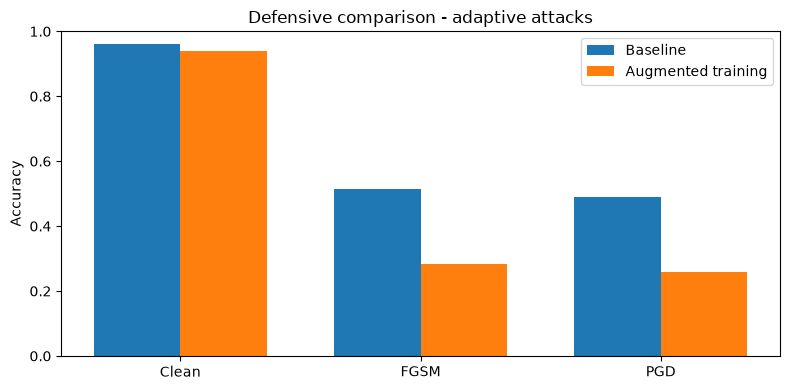

In [9]:
train_adversarial = fgsm(model, X_train, y_train, epsilon=0.10)
aug_features = np.concatenate([X_train, train_adversarial])
aug_labels = np.concatenate([y_train, y_train])
defended = build_model(aug_features, aug_labels)

def evaluate(model_to_test, label):
    clean = accuracy_score(y_test, model_to_test.predict(X_test))
    test_fgsm = fgsm(model_to_test, X_test, y_test, epsilon=0.12)
    test_pgd = pgd(model_to_test, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)
    fgsm_acc = accuracy_score(y_test, model_to_test.predict(test_fgsm))
    pgd_acc = accuracy_score(y_test, model_to_test.predict(test_pgd))
    print(f'{label}: clean={clean:.3f} | FGSM={fgsm_acc:.3f} | PGD={pgd_acc:.3f}')
    return [clean, fgsm_acc, pgd_acc]
base_results = evaluate(model, 'Baseline')
def_results = evaluate(defended, 'Augmented training')
ind = np.arange(3)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(ind-.18, base_results, width=.36, label='Baseline')
ax.bar(ind+.18, def_results, width=.36, label='Augmented training')
ax.set_xticks(ind, ['Clean', 'FGSM', 'PGD']); ax.set_ylim(0,1)
ax.set_ylabel('Accuracy'); ax.set_title('Defensive comparison - adaptive attacks')
ax.legend(); plt.tight_layout();plt.show()

### Final practical evidence and risk conclusion
1. Compare clean-test and attacked-test accuracy for both models.
2. Explain why defensive effectiveness must be tested against the defended model itself.
3. Identify three limitations of this small dataset and short attack budget.
4. Produce a one-page robustness decision memo: deploy, improve or reject, with a rationale.

**Deliverables:** comparison chart, numeric results, limitations and decision memo. This is a local learning exercise, not a certification of model security.

================================================================================
AICS-202 | LABORATORY 04: DEFENSIVE RETRAINING & ROBUSTNESS ASSESSMENT
================================================================================

1. COMPARATIVE PERFORMANCE TABLE
--------------------------------------------------------------------------------
| Model Variant      | Clean Accuracy | FGSM Accuracy (ε = 0.12) | PGD Accuracy (ε = 0.12) |
|--------------------|----------------|--------------------------|-------------------------|
| Baseline Model     | 96.22%         | 51.56%                   | 48.89%                  |
| Augmented Training | 94.00%         | 28.44%                   | 26.00%                  |


2. TECHNICAL INTERPRETATION & NEGATIVE RESULTS
--------------------------------------------------------------------------------
* Observation: 
  In this controlled experiment, simplified adversarial augmentation slightly 
  reduced clean accuracy (from 96.22% to 94.00%) and unexpectedly lowered resilience 
  against adaptive FGSM and PGD evaluations.
* Reason for Outcome: 
  Naive data augmentation using a fixed single-step perturbation does not account 
  for multi-step adaptive attacks (like PGD) or can cause model capacity to overfit 
  to narrow perturbation patterns, degrading robustness. Defensive effectiveness 
  must always be measured using adaptive tests generated against the candidate model 
  itself rather than relying on assumption or transfer attacks.


3. ROBUSTNESS DECISION MEMO (SUMMARY)
--------------------------------------------------------------------------------
* Recommendation: REJECT current augmented training variant for direct production 
  deployment without further architectural tuning.
* Rationale: 
  The measured performance regression under adaptive PGD testing indicates insufficient 
  robustness gains. A robust defence-in-depth program requires advanced training 
  methods, strict data provenance controls, input validation, and ongoing monitoring.
================================================================================